# Notebook 04: Carport Data Exploratie
___
In dit Jupyter Notebook wordt de exploratie gedaan op basis van de dataset uit het bestand [carport.parquet](./locatie_data/carport.parquet)

#### Uitgevoerde taken zijn:
* Data Exploratie
* Data Onderzoek
* Data Aanpassing
* Data Aanvulling

### Inladen
___
1. Libraries importeren en de map met de data vastleggen

In [187]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

#Map waar de parquet bestanden staan
DATA_DIR = Path.cwd().parent / "locatie_data"

2. De carport dataset inladen

In [188]:
df_carport = pd.read_parquet(DATA_DIR / "carport.parquet")

3. Eerste rijen bekijken

In [189]:
df_carport.head()

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,240308_hoofdaansluiting-e4393cd3dfdb_854d89ad9...,240308_hoofdaansluiting-e4393cd3dfdb_854d89ad9...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,240308_laadpaal1-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal1-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,240308_laadpaal2-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal2-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal3-e4393cd3dfdb,evcharger,240308_laadpaal3-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal3-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal3-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:00:00+01:00,NaN,electricity,overigverbruik-e4393cd3dfdb,powermeter,240308_overigverbruik-e4393cd3dfdb_a7612155098...,240308_overigverbruik-e4393cd3dfdb_a7612155098...,overigverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Algemene controle
___
1. Grootte, volgorde en datatypes van de dataset bekijken

In [190]:
print("Shape:", df_carport.shape)

#Staan de timestamps op volgorde?
print("Chronologisch:", df_carport["timestamp"].is_monotonic_increasing)

df_carport.info()

Shape: (4888431, 25)
Chronologisch: True
<class 'pandas.DataFrame'>
RangeIndex: 4888431 entries, 0 to 4888430
Data columns (total 25 columns):
 #   Column         Dtype                           
---  ------         -----                           
 0   timestamp      datetime64[us, Europe/Amsterdam]
 1   CO2EQ          float64                         
 2   CTYPE          str                             
 3   ENAME          str                             
 4   ETYPE          str                             
 5   source_zip     str                             
 6   source_csv     str                             
 7   source_folder  str                             
 8   CTYPEC         str                             
 9   ESTYPE         str                             
 10  forecast.ENE   float64                         
 11  forecast.POW   float64                         
 12  ENE            float64                         
 13  POW            float64                         
 14  CO2 

2. Aantal rijen per ENAME

In [191]:
df_carport["ENAME"].value_counts()

ENAME
totaalverbruik-e4393cd3dfdb            361138
laadpaal2-e4393cd3dfdb                 360889
laadpaal1-e4393cd3dfdb                 360517
hoofdaansluiting-e4393cd3dfdb          358041
overigverbruik-e4393cd3dfdb            356967
laadpaal3-e4393cd3dfdb                 353343
zonnepanelen-e4393cd3dfdb              345473
wijktotaalverbruik-e4393cd3dfdb        318470
wijkvirtuelehoofdmeter-e4393cd3dfdb    318195
wijktotaleopwek-e4393cd3dfdb           309497
laadpaalbus-e4393cd3dfdb               282308
laadpaaltesla-e4393cd3dfdb             281698
victronaccu-e4393cd3dfdb               259754
co2ele_combined                        158933
priceele_c911efafaa                    147634
odectprice_c911efafaa                   95109
laadpaal4-e4393cd3dfdb                  92220
laadpaal5-e4393cd3dfdb                  92220
forec-totaalverbruik-e4393cd3dfdb       17294
forec-zonnepanelen-e4393cd3dfdb         17294
priceele_123456                          1437
Name: count, dtype: int64

3. Aantal ingevulde waarden per kolom, per ENAME

> Hiermee is te zien welke kolommen bij welk apparaat horen

In [192]:
ingevulde_kolommen_per_ename = (df_carport.groupby("ENAME").count())

ingevulde_kolommen_per_ename

,timestamp,CO2EQ,CTYPE,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,forecast.ENE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
ENAME,,,,,,,,,,,,,,,,,,,,,
co2ele_combined,158933,158933,158933,158933,158933,158933,158933,0,0,0,...,0,0,0,0,0,0,0,0,0,0
forec-totaalverbruik-e4393cd3dfdb,17294,0,17294,17294,17294,17294,17294,17294,17294,8647,...,0,0,0,0,0,0,0,0,0,0
forec-zonnepanelen-e4393cd3dfdb,17294,0,17294,17294,17294,17294,17294,17294,17294,8647,...,0,0,0,0,0,0,0,0,0,0
hoofdaansluiting-e4393cd3dfdb,358041,0,358041,358041,358041,358041,358041,219821,0,0,...,78271,84446,145952,152130,138218,137072,137071,141751,141749,0
laadpaal1-e4393cd3dfdb,360517,0,360517,360517,360517,360517,360517,138108,0,0,...,0,70559,0,138235,129460,0,133599,0,138277,0
laadpaal2-e4393cd3dfdb,360889,0,360889,360889,360889,360889,360889,138107,0,0,...,0,70461,0,138135,129245,0,133501,0,138177,0
laadpaal3-e4393cd3dfdb,353343,0,353343,353343,353343,353343,353343,134340,0,0,...,0,66413,0,131748,124566,0,127124,0,131789,0
laadpaal4-e4393cd3dfdb,92220,0,92220,92220,92220,92220,92220,43790,0,0,...,0,6958,0,48416,40706,0,43781,0,48429,0
laadpaal5-e4393cd3dfdb,92220,0,92220,92220,92220,92220,92220,43790,0,0,...,0,6958,0,48417,40706,0,43782,0,48430,0


### Overzicht van de meetreeksen
___
1. Per ENAME het aantal rijen, unieke timestamps, eerste en laatste meting

> Dubbele timestamps = aantal rijen - unieke timestamps

In [193]:
#Samenvatting van de timestamps per ENAME
overzicht = (df_carport.groupby("ENAME").agg(
        aantal_rijen=("timestamp", "size"),
        unieke_timestamps=("timestamp", "nunique"),
        eerste_meting=("timestamp", "min"),
        laatste_meting=("timestamp", "max")
    )
)

#Extra rijen doordat een timestamp vaker voorkomt
overzicht["dubbele_timestamps"] = (overzicht["aantal_rijen"] - overzicht["unieke_timestamps"])

overzicht.sort_values("aantal_rijen", ascending=False)

,aantal_rijen,unieke_timestamps,eerste_meting,laatste_meting,dubbele_timestamps
ENAME,,,,,
totaalverbruik-e4393cd3dfdb,361138,222913,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138225
laadpaal2-e4393cd3dfdb,360889,222781,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138108
laadpaal1-e4393cd3dfdb,360517,222408,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138109
hoofdaansluiting-e4393cd3dfdb,358041,219820,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138221
overigverbruik-e4393cd3dfdb,356967,220886,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,136081
laadpaal3-e4393cd3dfdb,353343,219002,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,134341
zonnepanelen-e4393cd3dfdb,345473,207287,2024-03-08 01:05:00+01:00,2026-09-07 08:05:00+02:00,138186
wijktotaalverbruik-e4393cd3dfdb,318470,182389,2024-03-08 21:55:00+01:00,2026-09-07 08:05:00+02:00,136081
wijkvirtuelehoofdmeter-e4393cd3dfdb,318195,182114,2024-03-09 20:55:00+01:00,2026-09-07 08:05:00+02:00,136081


### Totaalverbruik bekijken
___
1. Alleen de rijen van totaalverbruik apart zetten

In [194]:
TOTAALVERBRUIK = "totaalverbruik-e4393cd3dfdb"

#Aparte dataframe met alleen totaalverbruik, gesorteerd op tijd
df_totaal = (df_carport[df_carport["ENAME"] == TOTAALVERBRUIK].copy()
             .sort_values("timestamp").reset_index(drop=True)
)

print("Aantal rijen:", len(df_totaal))
print("Unieke timestamps:", df_totaal["timestamp"].nunique())
print("Dubbele timestamps:", len(df_totaal) - df_totaal["timestamp"].nunique())

df_totaal.head()

Aantal rijen: 361138
Unieke timestamps: 222913
Dubbele timestamps: 138225


,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:05:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:10:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:15:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2. Alle rijen met een dubbele timestamp bekijken

> Vaak staat de meting verdeeld over 2 rijen (bv. één rij met COST en één rij met POW)

In [195]:
#keep=False zodat beide rijen van een dubbele timestamp getoond worden
df_dubbel = (df_totaal[df_totaal["timestamp"].duplicated(keep=False)].sort_values("timestamp"))

df_dubbel

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
59080,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59081,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
80037,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.000621,NaN,NaN,NaN,NaN,NaN
80038,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,35447531.0,NaN
80039,2025-01-14 09:25:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,0.005844,0.0,0.005844,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
356507,2026-06-20 03:45:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,19128467.0,NaN
356508,2026-06-20 03:50:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,0.0,0.000000,NaN,NaN,NaN
356509,2026-06-20 03:50:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,19128467.0,NaN
356510,2026-06-20 03:55:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,19128467.0,NaN


### POW bekijken
___
1. Timestamp en POW van totaalverbruik bekijken

In [196]:
df_totaal[["timestamp", "POW"]].head()

,timestamp,POW
0,2024-03-08 01:00:00+01:00,786.222222
1,2024-03-08 01:05:00+01:00,3108.181818
2,2024-03-08 01:10:00+01:00,3253.111111
3,2024-03-08 01:15:00+01:00,3249.264706
4,2024-03-08 01:20:00+01:00,1446.435897


2. Aantal ontbrekende POW waarden

In [197]:
print("Ontbrekende POW:", df_totaal["POW"].isna().sum())

Ontbrekende POW: 152752


3. Beschrijvende statistiek van POW

> Let op de negatieve minimumwaarde, verbruik zou niet negatief moeten zijn

In [198]:
df_totaal["POW"].describe().T

count    208386.000000
mean       1907.489846
std        3634.913964
min      -25072.572193
25%          39.120849
50%         167.578095
75%        1114.618921
max       35694.647059
Name: POW, dtype: float64

4. POW over de tijd plotten

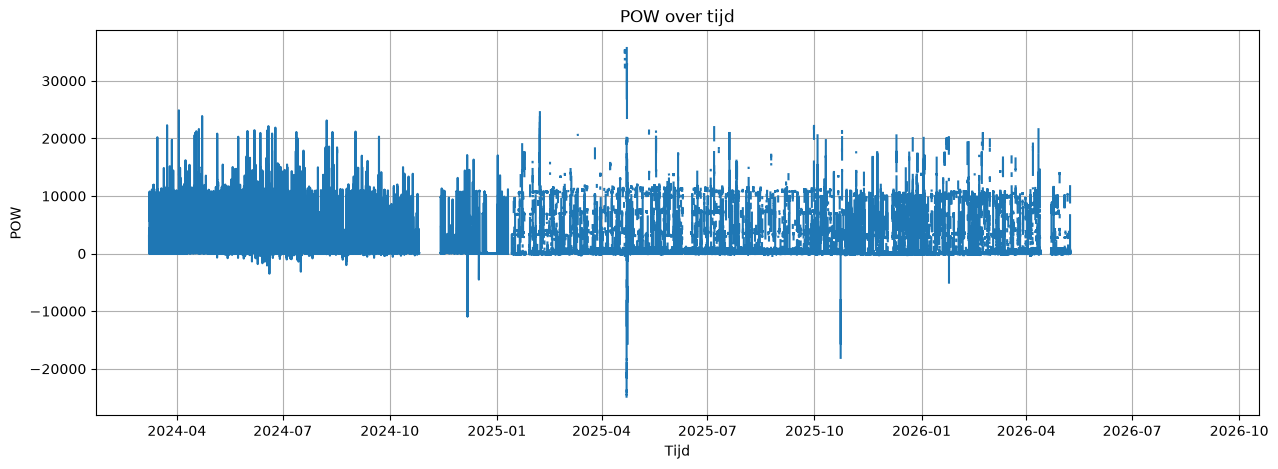

In [199]:
plt.figure(figsize=(15, 5))
plt.plot(df_totaal["timestamp"], df_totaal["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

5. Begin en einde van de meetreeks, en de laatste geldige POW

In [200]:
print("Eerste timestamp:", df_totaal["timestamp"].min())
print("Laatste timestamp:", df_totaal["timestamp"].max())

#Laatste timestamp waar POW ook echt gevuld is
print("Laatste timestamp met geldige POW:", df_totaal.loc[df_totaal["POW"].notna(), "timestamp"].max())

Eerste timestamp: 2024-03-08 01:00:00+01:00
Laatste timestamp: 2026-09-07 08:05:00+02:00
Laatste timestamp met geldige POW: 2026-09-02 08:10:00+02:00


6. Controleren of er per meting meerdere POW waarden zijn

> Groeperen op timestamp + CTYPE + CTYPEC + ENAME + ETYPE

In [201]:
#Alleen rijen waar POW aanwezig is
df_carport_pow = df_carport[df_carport["POW"].notna()].copy()

In [202]:
#Per combinatie tellen hoeveel POW waarden er zijn
controle_pow = (df_carport_pow.groupby(["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"], dropna=False)
    .agg(
        aantal_rijen=("POW", "size"),
        aantal_unieke_POW=("POW", "nunique"),
        min_POW=("POW", "min"),
        max_POW=("POW", "max")
    )
    .reset_index()
)

#Alleen combinaties met meer dan 1 POW waarde
controle_pow = controle_pow[controle_pow["aantal_rijen"] > 1]

controle_pow.head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,aantal_rijen,aantal_unieke_POW,min_POW,max_POW
468204,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,2,2,3646.764706,4056.000000
468205,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,2,2,-7242.800000,-23.500000
468206,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,2,2,927.071429,4033.400000
468207,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,2,2,3979.625000,4082.363636
468208,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,2,2,0.000250,0.000313
468209,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal3-e4393cd3dfdb,evcharger,2,2,0.000340,0.000389
468212,2024-10-05 20:10:00+02:00,electricity,NaN,overigverbruik-e4393cd3dfdb,powermeter,2,2,-26.057143,-11.382022
468213,2024-10-05 20:10:00+02:00,electricity,NaN,wijktotaalverbruik-e4393cd3dfdb,powermeter,2,2,9630.992593,10295.836735
468214,2024-10-05 20:10:00+02:00,electricity,NaN,wijktotaleopwek-e4393cd3dfdb,powermeter,2,2,-12257.200000,-23.500000
468215,2024-10-05 20:10:00+02:00,electricity,NaN,wijkvirtuelehoofdmeter-e4393cd3dfdb,powermeter,2,2,9157.367647,10230.265306


In [203]:
#Alleen rijen waar POW aanwezig is
df_pow = df_carport[df_carport["POW"].notna()].copy()

#Zoektype van Pieter
filter = ["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"]

dubbel = df_pow.duplicated(subset=filter,keep=False)

dubbele_pow = (df_pow.loc[dubbel].sort_values(filter))

dubbele_pow

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
527103,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527104,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527111,2024-10-05 20:10:00+02:00,NaN,electricity,zonnepanelen-e4393cd3dfdb,solarpanel,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,zonnepanelen-e4393cd3dfdb,generation,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527112,2024-10-05 20:10:00+02:00,NaN,electricity,zonnepanelen-e4393cd3dfdb,solarpanel,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,zonnepanelen-e4393cd3dfdb,generation,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527091,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527092,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527093,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527094,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527095,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527096,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [204]:
df_carport["CTYPE"].unique()

<ArrowStringArray>
['electricity']
Length: 1, dtype: str

In [205]:
df_carport["CTYPEC"].unique()

<ArrowStringArray>
['supply', nan, 'consumption', 'generation', 'storage']
Length: 5, dtype: str

### ENAME
___
1. Kijken naar alle ENAME variabelen

> Laadpaal 1-5 + Tesla & Bus
>
> Overig gebruik [Gereedschap, lampen?]
>
> Accu
>
> Zonnepanelen
>
> Hoofdaansluiting
>
> Totaalverbruik
>
> Wijktotaalverbruik
>
> Wijktotaalopwekking
>
> Voorspellingen (Totaalverbruik, Zonnepanelen)
>
> Samengevoegde colommen (Price + energie) (Odect + Price) (Price + energie wijk) (Co2 + energie)

In [206]:
df_carport["ENAME"].unique()

<ArrowStringArray>
[      'hoofdaansluiting-e4393cd3dfdb',              'laadpaal1-e4393cd3dfdb',
              'laadpaal2-e4393cd3dfdb',              'laadpaal3-e4393cd3dfdb',
         'overigverbruik-e4393cd3dfdb',         'totaalverbruik-e4393cd3dfdb',
           'zonnepanelen-e4393cd3dfdb',            'laadpaalbus-e4393cd3dfdb',
          'laadpaaltesla-e4393cd3dfdb',     'wijktotaalverbruik-e4393cd3dfdb',
        'wijktotaleopwek-e4393cd3dfdb', 'wijkvirtuelehoofdmeter-e4393cd3dfdb',
                     'co2ele_combined',               'odectprice_c911efafaa',
                 'priceele_c911efafaa',            'victronaccu-e4393cd3dfdb',
   'forec-totaalverbruik-e4393cd3dfdb',     'forec-zonnepanelen-e4393cd3dfdb',
              'laadpaal4-e4393cd3dfdb',              'laadpaal5-e4393cd3dfdb',
                     'priceele_123456']
Length: 21, dtype: str

In [207]:
Co2ele = df_carport[df_carport["ENAME"] == "co2ele_combined"]
Co2ele

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
91871,2024-04-10 17:05:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91872,2024-04-10 17:10:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91873,2024-04-10 17:15:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91874,2024-04-10 17:20:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91875,2024-04-10 17:25:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4818882,2026-06-20 03:35:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4818914,2026-06-20 03:40:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4818946,2026-06-20 03:45:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4818978,2026-06-20 03:50:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2. De niet nutige Enames droppen

In [208]:
drop_values = ["co2ele_combined", "odectprice_c911efafaa", "priceele_123456", "priceele_c911efafaa", "forec-zonnepanelen-e4393cd3dfdb", "forec-totaalverbruik-e4393cd3dfdb"]

df_carport = df_carport[~df_carport["ENAME"].isin(drop_values)]


In [209]:
kolommen = [
    "timestamp",
    "CTYPE",
    "CTYPEC",
    "ENAME",
    "ETYPE",
    "POW"
]

dubbele_pow[kolommen].head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,POW
527103,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,3646.764706
527104,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,4056.000000
527111,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,-7242.800000
527112,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,-23.500000
527091,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,927.071429
527092,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,4033.400000
527093,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,3979.625000
527094,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,4082.363636
527095,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,0.000313
527096,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,0.000250


3. Geef de kolommen bruikbare namen

In [210]:
# Source - https://stackoverflow.com/a/11354850
# Posted by lexual, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-01, License - CC BY-SA 4.0

dubbele_pow.rename(columns={'CTYPE': 'electricity',
                   'CTYPEC': 'energie_types',
                   'ENAME': 'apparaat',
                   'ETYPE': 'apparaat_type',
                   'POW': 'energie'
                   }, inplace=True)

### Verdeling ENAME en ETYPE
___
1. Aantal rijen per ENAME in een grafiek

> De niet nuttige ENAMEs zijn hierboven al gedropt, dus dit is de verdeling van de overgebleven apparaten
>
> De code `-e4393cd3dfdb` achter elke naam wordt weggehaald zodat de grafiek leesbaar blijft

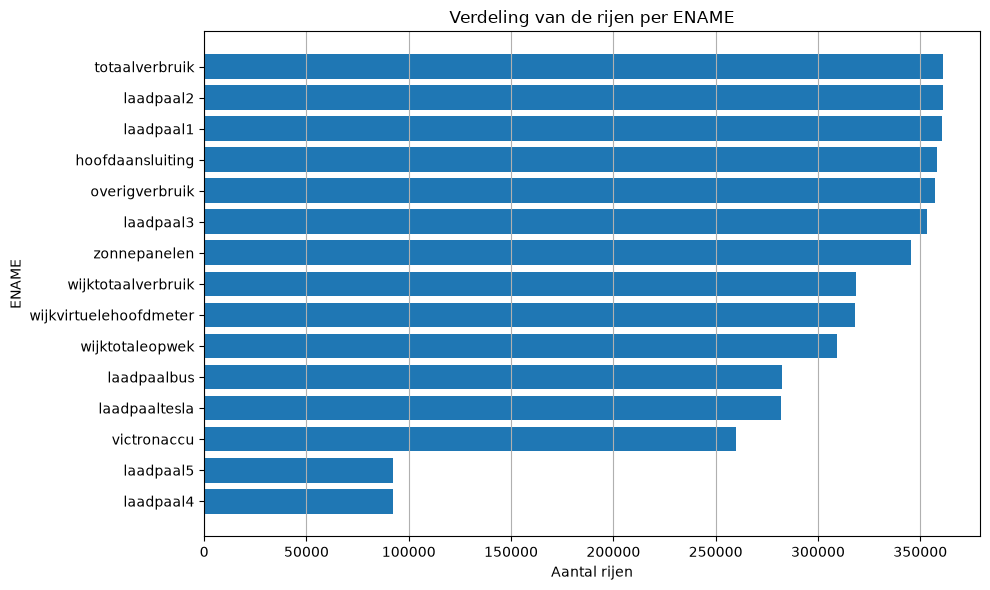

In [211]:
#Aantal rijen per ENAME, zonder de code achter de naam
ename_telling = (df_carport["ENAME"].str.replace("-e4393cd3dfdb", "").value_counts().sort_values())

plt.figure(figsize=(10, 6))
plt.barh(ename_telling.index, ename_telling.values)

plt.xlabel("Aantal rijen")
plt.ylabel("ENAME")
plt.title("Verdeling van de rijen per ENAME")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

### ETYPE
___
1. Welke ETYPEs er zijn en hoe vaak ze voorkomen, ook als percentage

In [212]:
etype_overzicht = pd.DataFrame({
    "aantal_rijen": df_carport["ETYPE"].value_counts(),
    "percentage": (df_carport["ETYPE"].value_counts(normalize=True) * 100).round(2)
})

etype_overzicht

,aantal_rijen,percentage
ETYPE,,
powermeter,2025271,45.50
evcharger,1823195,40.96
solarpanel,345473,7.76
battery,256791,5.77


2. Aantal rijen per ETYPE in een grafiek

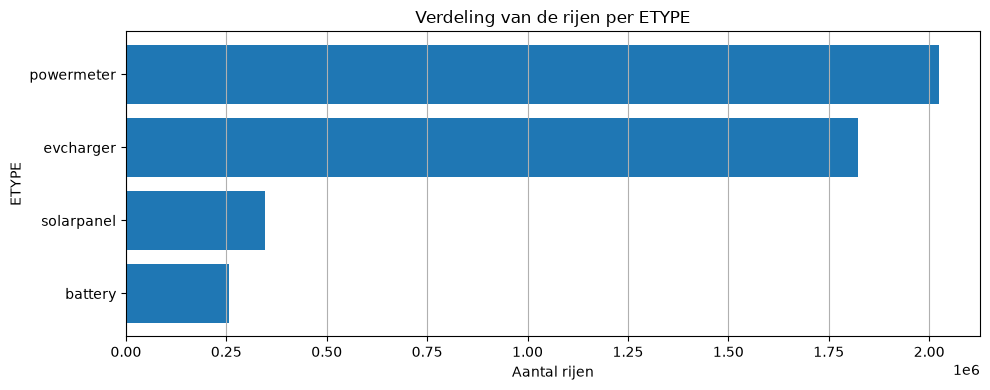

In [213]:
etype_telling = df_carport["ETYPE"].value_counts().sort_values()

plt.figure(figsize=(10, 4))
plt.barh(etype_telling.index, etype_telling.values)

plt.xlabel("Aantal rijen")
plt.ylabel("ETYPE")
plt.title("Verdeling van de rijen per ETYPE")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

3. Welke ENAMEs bij welk ETYPE horen

> Hiermee is te zien welke apparaten onder hetzelfde type vallen (bv. alle laadpalen onder evcharger)

In [214]:
#Kruistabel van ENAME tegenover ETYPE
ename_per_etype = pd.crosstab(df_carport["ENAME"].str.replace("-e4393cd3dfdb", ""), df_carport["ETYPE"])

ename_per_etype

ETYPE,battery,evcharger,powermeter,solarpanel
ENAME,,,,
hoofdaansluiting,0,0,358041,0
laadpaal1,0,360517,0,0
laadpaal2,0,360889,0,0
laadpaal3,0,353343,0,0
laadpaal4,0,92220,0,0
laadpaal5,0,92220,0,0
laadpaalbus,0,282308,0,0
laadpaaltesla,0,281698,0,0
overigverbruik,0,0,356967,0


4. Welke kolommen per ETYPE gevuld zijn, als percentage

> Kolommen die bij een ETYPE (bijna) altijd leeg zijn worden niet gemeten voor dat type

In [215]:
#Percentage ingevulde waarden per kolom, per ETYPE
gevuld_per_etype = (df_carport.drop(columns=["source_zip", "source_csv", "source_folder"])
                    .groupby("ETYPE").agg(lambda kolom: kolom.notna().mean() * 100).round(1)
)

gevuld_per_etype.T

ETYPE,battery,evcharger,powermeter,solarpanel
timestamp,100.0,100.0,100.0,100.0
CO2EQ,0.0,0.0,0.0,0.0
CTYPE,100.0,100.0,100.0,100.0
ENAME,100.0,100.0,100.0,100.0
CTYPEC,50.9,41.9,48.8,60.0
ESTYPE,0.0,0.0,0.0,0.0
forecast.ENE,0.0,0.0,0.0,0.0
forecast.POW,0.0,0.0,0.0,0.0
ENE,50.3,54.6,58.9,58.8
POW,45.8,45.3,54.4,52.2


5. Statistiek van POW per ETYPE

> Negatieve POW betekent teruglevering (zoals bij de zonnepanelen)

In [216]:
pow_per_etype = df_carport.groupby("ETYPE")["POW"].describe()

pow_per_etype

,count,mean,std,min,25%,50%,75%,max
ETYPE,,,,,,,,
battery,117627.0,3.997454e+02,6.876758e+03,-3.536584e+04,-1529.863376,95.941176,393.292560,3.263411e+04
evcharger,826768.0,4.271920e+02,1.819004e+03,-2.000000e+00,0.000000,0.000000,0.000298,1.146183e+04
powermeter,1102551.0,4.764827e+13,1.925892e+18,-1.403426e+21,-155.455844,86.125000,3472.206171,1.455960e+21
solarpanel,180223.0,-8.050830e+03,1.236975e+04,-6.333825e+04,-11723.158288,-1011.304348,-23.500000,7.237143e+01


6. Spreiding van POW per ETYPE in een boxplot

> Uitschieters worden niet getoond zodat de boxen zichtbaar blijven

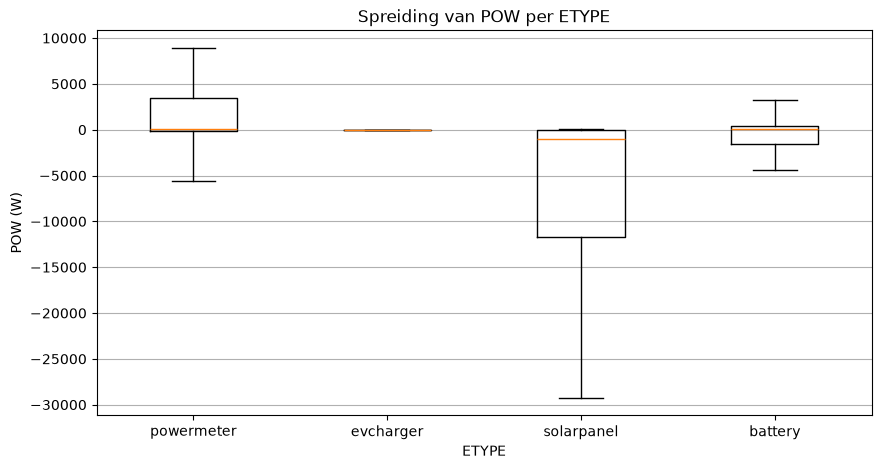

In [217]:
#Per ETYPE de geldige POW waarden verzamelen
etypes = df_carport["ETYPE"].dropna().unique()
pow_waarden = [df_carport.loc[(df_carport["ETYPE"] == etype) & df_carport["POW"].notna(), "POW"] for etype in etypes]

plt.figure(figsize=(10, 5))
plt.boxplot(pow_waarden, tick_labels=etypes, showfliers=False)

plt.xlabel("ETYPE")
plt.ylabel("POW (W)")
plt.title("Spreiding van POW per ETYPE")
plt.grid(axis="y")
plt.show()

7. Periode waarin elk ETYPE gemeten is

In [218]:
periode_per_etype = (df_carport.groupby("ETYPE").agg(
        eerste_meting=("timestamp", "min"),
        laatste_meting=("timestamp", "max"),
        aantal_enames=("ENAME", "nunique")
    )
)

periode_per_etype

,eerste_meting,laatste_meting,aantal_enames
ETYPE,,,
battery,2025-02-25 14:15:00+01:00,2026-09-07 08:05:00+02:00,1
evcharger,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,7
powermeter,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,7
solarpanel,2024-03-08 01:05:00+01:00,2026-09-07 08:05:00+02:00,1


### Evcharger verbruik
___
In de statistiek per ETYPE lijkt evcharger geen verbruik te hebben, maar dat klopt niet helemaal:

> Mediaan = 0 W en 75% = 0.0003 W, dus meer dan driekwart van de metingen staat de laadpaal stil
>
> Gemiddelde = 427 W en max = 11.461 W, dus er wordt wel degelijk geladen, alleen in korte periodes
>
> Waarden als 0.0003 W zijn sensorruis / stand-by en geen echt verbruik

Daarom worden de laadmomenten hieronder apart van de stilstand bekeken.

1. Alleen de POW metingen van de laadpalen apart zetten

> Dubbele timestamps per laadpaal worden samengevoegd met het gemiddelde

In [219]:
#Alleen evcharger rijen met een POW waarde
df_laad = df_carport[(df_carport["ETYPE"] == "evcharger") & df_carport["POW"].notna()][["timestamp", "ENAME", "POW"]].copy()

#Korte naam zonder de code erachter
df_laad["ENAME"] = df_laad["ENAME"].str.replace("-e4393cd3dfdb", "")

#Dubbele timestamps per laadpaal samenvoegen
df_laad = df_laad.groupby(["timestamp", "ENAME"], as_index=False)["POW"].mean()

print("Aantal metingen:", len(df_laad))
df_laad.head()

Aantal metingen: 826765


,timestamp,ENAME,POW
0,2024-03-08 01:00:00+01:00,laadpaal1,0.000353
1,2024-03-08 01:00:00+01:00,laadpaal2,316.100317
2,2024-03-08 01:00:00+01:00,laadpaal3,0.000465
3,2024-03-08 01:05:00+01:00,laadpaal1,0.000471
4,2024-03-08 01:05:00+01:00,laadpaal2,3315.222222


2. Statistiek van POW per laadpaal

In [220]:
df_laad.groupby("ENAME")["POW"].describe()

,count,mean,std,min,25%,50%,75%,max
ENAME,,,,,,,,
laadpaal1,208993.0,247.316021,1321.771048,0.0,0.0,0.0,0.000275,11079.548387
laadpaal2,209154.0,365.888600,1463.037419,0.0,0.0,0.0,0.000318,10943.078125
laadpaal3,204468.0,294.768859,1238.573927,0.0,0.0,0.0,0.000337,10859.528000
laadpaal4,40709.0,12.904151,310.087366,0.0,0.0,0.0,0.000000,11119.310881
laadpaal5,40709.0,3.880760,167.934226,0.0,0.0,0.0,0.000000,8010.236264
laadpaalbus,60069.0,1292.200233,3471.106518,-1.0,0.0,0.0,0.416667,11216.414286
laadpaaltesla,62663.0,1378.724558,3466.991774,-2.0,0.0,0.0,1.500000,11461.826087


3. Bepalen wanneer een laadpaal aan het laden is

> Grens van 100 W: alles daaronder is ruis of stand-by

In [221]:
LAAD_GRENS = 100

#True als de laadpaal op dat moment echt aan het laden is
df_laad["laden"] = df_laad["POW"] > LAAD_GRENS

#Percentage van de metingen waarin geladen wordt, per laadpaal
laad_percentage = (df_laad.groupby("ENAME")["laden"].mean() * 100).round(2).sort_values()

laad_percentage

ENAME
laadpaal5         0.06
laadpaal4         0.51
laadpaal1         4.54
laadpaal3         6.81
laadpaal2         7.69
laadpaalbus      12.50
laadpaaltesla    15.42
Name: laden, dtype: float64

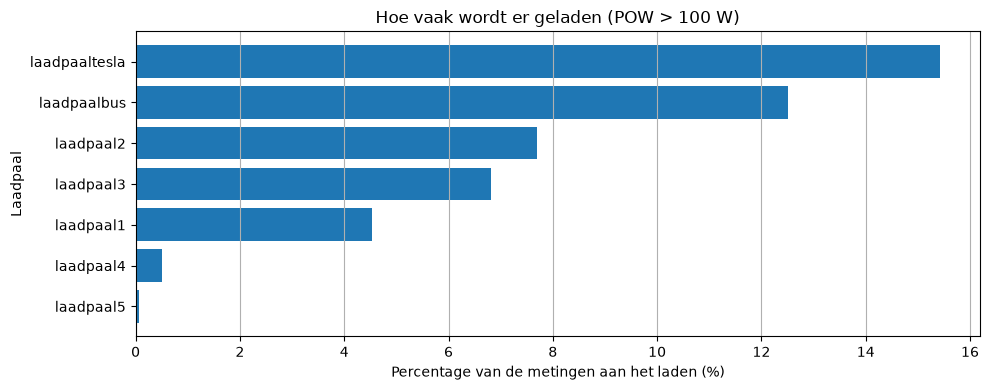

In [222]:
plt.figure(figsize=(10, 4))
plt.barh(laad_percentage.index, laad_percentage.values)

plt.xlabel("Percentage van de metingen aan het laden (%)")
plt.ylabel("Laadpaal")
plt.title(f"Hoe vaak wordt er geladen (POW > {LAAD_GRENS} W)")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

4. Verdeling van het laadvermogen, alleen tijdens het laden

> Pieken rond vaste waarden (bv. ~3.7 kW, ~7.4 kW of ~11 kW) laten zien met welk vermogen de auto's laden

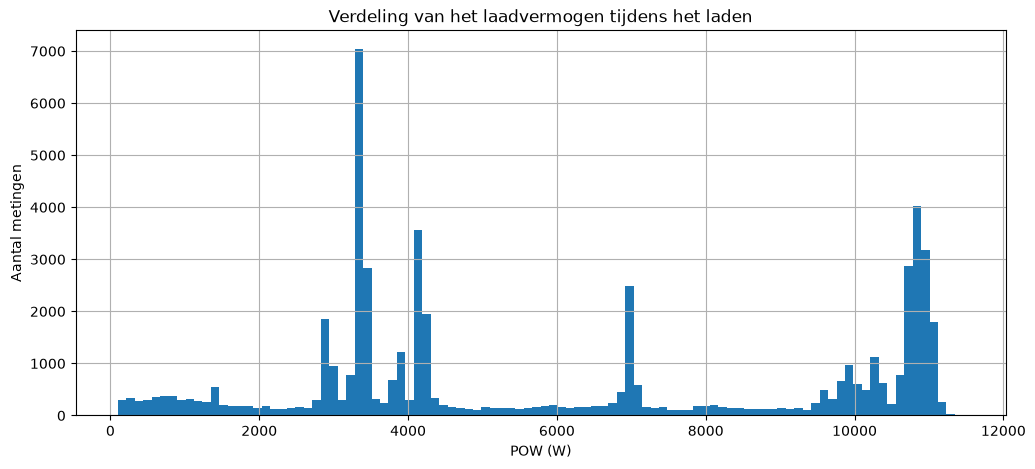

In [223]:
#Alleen de momenten waarop echt geladen wordt
df_laden = df_laad[df_laad["laden"]]

plt.figure(figsize=(12, 5))
plt.hist(df_laden["POW"], bins=100)

plt.xlabel("POW (W)")
plt.ylabel("Aantal metingen")
plt.title("Verdeling van het laadvermogen tijdens het laden")
plt.grid()
plt.show()

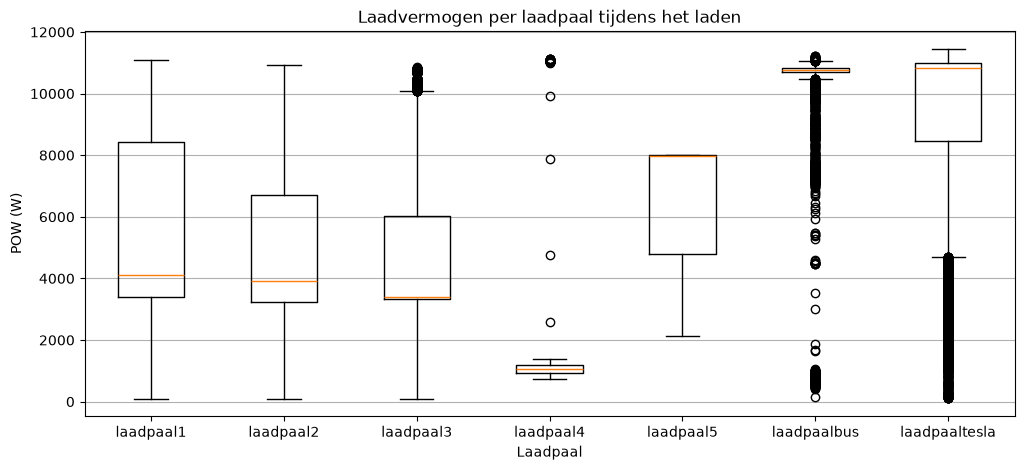

In [224]:
#Boxplot per laadpaal, alleen tijdens het laden
laadpalen = sorted(df_laden["ENAME"].unique())
pow_laden = [df_laden.loc[df_laden["ENAME"] == laadpaal, "POW"] for laadpaal in laadpalen]

plt.figure(figsize=(12, 5))
plt.boxplot(pow_laden, tick_labels=laadpalen)

plt.xlabel("Laadpaal")
plt.ylabel("POW (W)")
plt.title("Laadvermogen per laadpaal tijdens het laden")
plt.grid(axis="y")
plt.show()

5. Op welk uur van de dag wordt er geladen

> Belangrijk voor het project: laden overdag (zon) is gunstig, laden 's avonds/'s nachts haalt stroom van het net

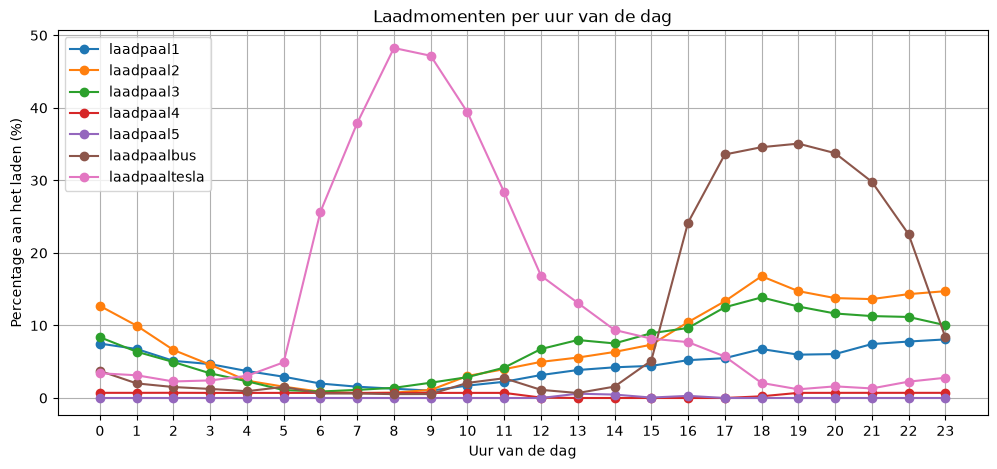

In [225]:
df_laad["uur"] = df_laad["timestamp"].dt.hour

#Percentage aan het laden per uur, per laadpaal
laden_per_uur = (df_laad.groupby(["uur", "ENAME"])["laden"].mean() * 100).unstack()

plt.figure(figsize=(12, 5))
for laadpaal in laden_per_uur.columns:
    plt.plot(laden_per_uur.index, laden_per_uur[laadpaal], marker="o", label=laadpaal)

plt.xlabel("Uur van de dag")
plt.ylabel("Percentage aan het laden (%)")
plt.title("Laadmomenten per uur van de dag")
plt.xticks(range(24))
plt.legend()
plt.grid()
plt.show()

6. Geladen energie per week, voor alle laadpalen samen

> Energie per meting (kWh) = POW (W) * 5/60 uur / 1000
>
> Weken met minder dan de helft van de metingen worden niet getoond, anders lijkt het alsof er 0 kWh geladen is terwijl de data ontbreekt (zoals vanaf mei 2026)

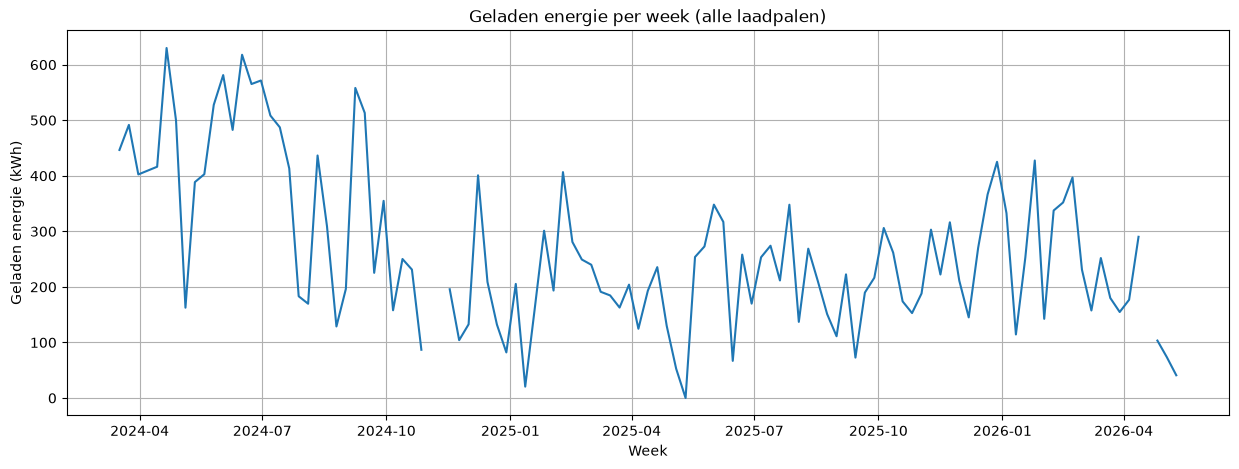

Totaal geladen (kWh): 29432
Weken zonder (genoeg) data: 21


In [226]:
#Aantal metingen in een volledige week (elke 5 minuten)
METINGEN_PER_WEEK = 7 * 24 * 12
MIN_METINGEN = METINGEN_PER_WEEK * 0.5

#Energie per meting van 5 minuten in kWh
df_laad["kWh"] = df_laad["POW"].clip(lower=0) * (5 / 60) / 1000

#Optellen per week
kwh_per_week = df_laad.set_index("timestamp")["kWh"].resample("W").sum()

#Aantal unieke timestamps per week, om weken zonder data te herkennen
metingen_per_week = df_laad.drop_duplicates("timestamp").set_index("timestamp")["kWh"].resample("W").size()

#Weken met te weinig metingen leeg maken
kwh_per_week = kwh_per_week.where(metingen_per_week >= MIN_METINGEN)

plt.figure(figsize=(15, 5))
plt.plot(kwh_per_week.index, kwh_per_week.values)

plt.xlabel("Week")
plt.ylabel("Geladen energie (kWh)")
plt.title("Geladen energie per week (alle laadpalen)")
plt.grid()
plt.show()

print("Totaal geladen (kWh):", round(df_laad["kWh"].sum()))
print("Weken zonder (genoeg) data:", kwh_per_week.isna().sum())

7. Wat de batterij per week heeft gedaan, naast het laden van de auto's

> Batterij = victronaccu, gemeten vanaf februari 2025, daarvoor is er dus geen data
>
> Aanname: positieve POW = batterij laadt op, negatieve POW = batterij levert stroom

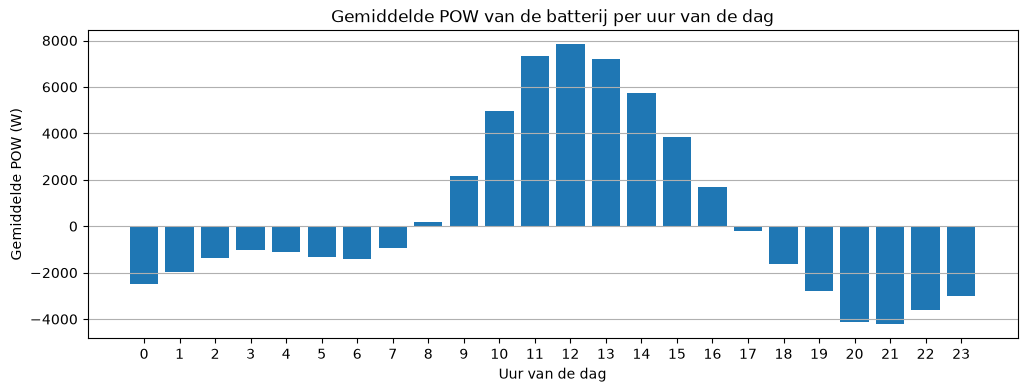

In [227]:
#Alleen de POW metingen van de batterij, dubbele timestamps samengevoegd
accu_pow = (df_carport[(df_carport["ENAME"] == "victronaccu-e4393cd3dfdb") & df_carport["POW"].notna()]
            .groupby("timestamp")["POW"].mean()
)

#Gemiddelde POW per uur van de dag, om de aanname over plus en min te controleren
accu_per_uur = accu_pow.groupby(accu_pow.index.hour).mean()

plt.figure(figsize=(12, 4))
plt.bar(accu_per_uur.index, accu_per_uur.values)

plt.xlabel("Uur van de dag")
plt.ylabel("Gemiddelde POW (W)")
plt.title("Gemiddelde POW van de batterij per uur van de dag")
plt.xticks(range(24))
plt.grid(axis="y")
plt.show()

> Controle: overdag (zon) zou de POW vooral positief moeten zijn (opladen) en 's avonds negatief (stroom leveren). Is dit andersom, dan moeten laden en ontladen hieronder omgedraaid worden

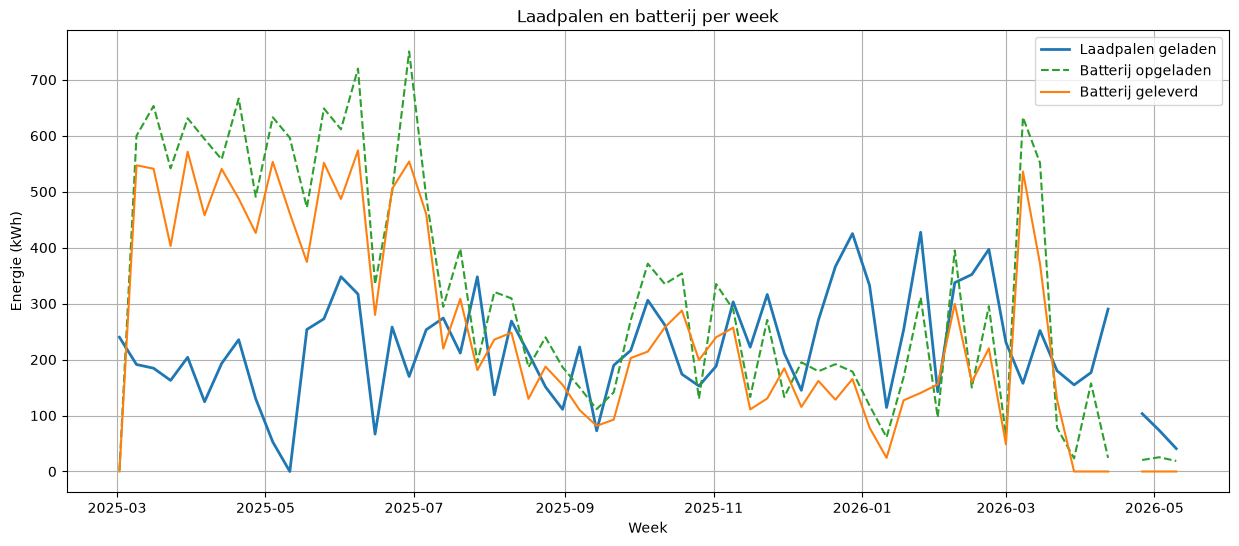

In [228]:
#Energie per meting in kWh, gesplitst in opladen en stroom leveren
accu_kwh = pd.DataFrame({
    "opgeladen": accu_pow.clip(lower=0) * (5 / 60) / 1000,
    "geleverd": accu_pow.clip(upper=0).abs() * (5 / 60) / 1000
})

#Optellen per week en weken met te weinig metingen leeg maken
accu_per_week = accu_kwh.resample("W").sum()
accu_metingen = accu_kwh.resample("W").size()
accu_per_week = accu_per_week.where(accu_metingen >= MIN_METINGEN)

#Alleen de weken waarin de batterij gemeten is, zodat beide lijnen over dezelfde periode gaan
start_accu = accu_per_week.dropna().index.min()
laad_vanaf_accu = kwh_per_week[kwh_per_week.index >= start_accu]

#Alles in een grafiek, zelfde eenheid (kWh) dus een y-as
plt.figure(figsize=(15, 6))
plt.plot(laad_vanaf_accu.index, laad_vanaf_accu.values, color="tab:blue", linewidth=2, label="Laadpalen geladen")
plt.plot(accu_per_week.index, accu_per_week["opgeladen"], color="tab:green", linestyle="--", label="Batterij opgeladen")
plt.plot(accu_per_week.index, accu_per_week["geleverd"], color="tab:orange", label="Batterij geleverd")

plt.xlabel("Week")
plt.ylabel("Energie (kWh)")
plt.title("Laadpalen en batterij per week")
plt.legend()
plt.grid()
plt.show()

# Grafiek gemaakt met hulp can Claude Opus 5.5 (Anthropic 2026)
# Promt:Ik heb deze grafiek, nu wil ik de grafiek met accu waarden erbij stoppen om te kijken of er correlatie is, zou je hier mee kunnen helpen?
# Meegestuurede bijlage: de grafiek van EVcharger 6.

> Correlatie tussen de laadpalen en de batterij per week: dicht bij 1 = ze gaan samen omhoog en omlaag, rond 0 = geen verband


In [229]:
#Alleen weken waarin beide gemeten zijn
week_vergelijking = pd.concat([kwh_per_week.rename("laadpalen"), accu_per_week], axis=1).dropna()

week_vergelijking.corr().round(2)


,laadpalen,opgeladen,geleverd
laadpalen,1.00,0.02,-0.02
opgeladen,0.02,1.00,0.97
geleverd,-0.02,0.97,1.00


> Opgeladen is altijd iets hoger dan geleverd door verlies in de batterij. Een groot verschil kan ook op ontbrekende metingen wijzen

In [230]:
#Totalen en het rendement van de batterij
print("Totaal opgeladen (kWh):", round(accu_kwh["opgeladen"].sum()))
print("Totaal geleverd (kWh):", round(accu_kwh["geleverd"].sum()))
print(f"Rendement: {accu_kwh['geleverd'].sum() / accu_kwh['opgeladen'].sum() * 100:.1f}%")

Totaal opgeladen (kWh): 19588
Totaal geleverd (kWh): 15670
Rendement: 80.0%


8. Hoeveel van het laden had door de zonnepanelen gedekt kunnen worden

> Per timestamp: laadvermogen van alle laadpalen samen tegenover de opwek van de zonnepanelen
>
> Zonnepanelen POW is negatief (opwek), daarom wordt de absolute waarde gebruikt

In [231]:
#Totaal laadvermogen per timestamp
laad_totaal = df_laad.groupby("timestamp")["POW"].sum().clip(lower=0)

#Opwek van de zonnepanelen per timestamp
zon = (df_carport[(df_carport["ENAME"] == "zonnepanelen-e4393cd3dfdb") & df_carport["POW"].notna()]
       .groupby("timestamp")["POW"].mean().clip(upper=0).abs()
)

#Alleen timestamps waar beide gemeten zijn
laad_zon = pd.concat([laad_totaal.rename("laden"), zon.rename("zon")], axis=1, join="inner")

#Deel van het laadvermogen dat de zon tegelijk opwekt
laad_zon["gedekt"] = laad_zon[["laden", "zon"]].min(axis=1)

dekking = laad_zon["gedekt"].sum() / laad_zon["laden"].sum() * 100
print(f"Percentage van het laden dat door de zon gedekt wordt: {dekking:.1f}%")

Percentage van het laden dat door de zon gedekt wordt: 40.9%


### Onmogelijke POW waarden
___
**Wat is POW?**

POW is het vermogen in watt: hoe hard er op dat moment stroom door een apparaat of kabel loopt. Ter vergelijking:

> Een waterkoker gebruikt ongeveer 2.000 W
>
> Een laadpaal laadt een auto met maximaal ongeveer 11.000 W (11 kW) 
>
> Een gemiddeld huis gebruikt zelden meer dan 10.000 W tegelijk

- [Bron 1](https://wattever.nl/laadsnelheid-thuislaadpaal/)
- [Bron 2](https://www.anwb.nl/energie/energieverbruik/4-personen)

**Wat is het probleem?**

In de statistiek per ETYPE staat bij powermeter een maximum van 1,4·10²¹ W. Dat is een 1 met 21 nullen. Alle elektriciteitscentrales op aarde samen leveren ongeveer 9·10¹² W, dus deze meting is meer dan 100 miljoen keer zoveel als de hele wereld kan opwekken. Zulke waarden zijn **onmogelijk** en komen door een fout in de meter of bij het opslaan van de data, niet door echt verbruik.

Eén zo'n waarde maakt het gemiddelde en elke grafiek onbruikbaar, en een voorspellingsmodel zou er volledig door in de war raken. Daarom worden ze hieronder opgespoord en weggehaald.

1. Per apparaat de laagste en hoogste POW waarde bekijken

In [232]:
#Korte naam zonder de code erachter
df_carport["apparaat_kort"] = df_carport["ENAME"].str.replace("-e4393cd3dfdb", "")

#Laagste en hoogste POW per apparaat
pow_bereik = df_carport.groupby("apparaat_kort")["POW"].agg(["min", "max", "count"])

pow_bereik

,min,max,count
apparaat_kort,,,
hoofdaansluiting,-6.213176e+04,2.968922e+04,203710
laadpaal1,0.000000e+00,1.107955e+04,208994
laadpaal2,0.000000e+00,1.094308e+04,209155
laadpaal3,0.000000e+00,1.085953e+04,204469
laadpaal4,0.000000e+00,1.111931e+04,40709
laadpaal5,0.000000e+00,8.010236e+03,40709
laadpaalbus,-1.000000e+00,1.121641e+04,60069
laadpaaltesla,-2.000000e+00,1.146183e+04,62663
overigverbruik,-3.208346e+04,3.538375e+04,205077


2. Een grens kiezen voor wat fysiek mogelijk is

> De carport heeft één aansluiting op het net. Die kan maar een beperkte hoeveelheid stroom leveren, ruim onder de 100.000 W (100 kW)
>
> Alles boven de 100 kW of onder de -100 kW kan dus nooit echt gemeten zijn


In [233]:
#Grens in watt, alles daarbuiten is onmogelijk
MAX_VERMOGEN = 100_000

#True als de POW waarde buiten de grens valt
onmogelijk = df_carport["POW"].abs() > MAX_VERMOGEN

print("Aantal onmogelijke POW waarden:", onmogelijk.sum())
print(f"Percentage van alle POW waarden: {onmogelijk.sum() / df_carport['POW'].notna().sum() * 100:.4f}%")

Aantal onmogelijke POW waarden: 15
Percentage van alle POW waarden: 0.0007%


3. Bij welke apparaten de onmogelijke waarden voorkomen

In [234]:
#Aantal onmogelijke waarden per apparaat
onmogelijk_per_apparaat = df_carport[onmogelijk].groupby("apparaat_kort").size().sort_values(ascending=False)

onmogelijk_per_apparaat

apparaat_kort
wijktotaleopwek           10
wijkvirtuelehoofdmeter     4
wijktotaalverbruik         1
dtype: int64

4. Wanneer de onmogelijke waarden voorkomen

> Als ze allemaal op een paar dagen vallen, wijst dat op een storing of een moment waarop de meter is vervangen of opnieuw gestart

In [235]:
#Alleen de onmogelijke rijen, met de belangrijkste kolommen
df_onmogelijk = df_carport.loc[onmogelijk, ["timestamp", "apparaat_kort", "ETYPE", "POW"]].sort_values("timestamp")

#Aantal onmogelijke waarden per dag
onmogelijk_per_dag = df_onmogelijk.groupby(df_onmogelijk["timestamp"].dt.date).size()

print("Aantal dagen met onmogelijke waarden:", len(onmogelijk_per_dag))
onmogelijk_per_dag.sort_values(ascending=False).head(10)

Aantal dagen met onmogelijke waarden: 4


timestamp
2026-05-08    9
2026-05-07    3
2025-09-24    2
2026-03-26    1
dtype: int64

In [236]:
df_onmogelijk.head(20)

,timestamp,apparaat_kort,ETYPE,POW
2827325,2025-09-24 09:50:00+02:00,wijktotaalverbruik,powermeter,-1.403426e+21
2827327,2025-09-24 09:50:00+02:00,wijktotaleopwek,powermeter,1.455960e+21
4404423,2026-03-26 11:35:00+01:00,wijktotaleopwek,powermeter,-1.012922e+05
4701182,2026-05-07 12:40:00+02:00,wijktotaleopwek,powermeter,-1.020519e+05
4701184,2026-05-07 12:40:00+02:00,wijkvirtuelehoofdmeter,powermeter,-1.017000e+05
4701374,2026-05-07 13:10:00+02:00,wijktotaleopwek,powermeter,-1.045165e+05
4710398,2026-05-08 12:40:00+02:00,wijktotaleopwek,powermeter,-1.039940e+05
4710400,2026-05-08 12:40:00+02:00,wijkvirtuelehoofdmeter,powermeter,-1.036163e+05
4710558,2026-05-08 13:05:00+02:00,wijktotaleopwek,powermeter,-1.010347e+05
4710718,2026-05-08 13:30:00+02:00,wijktotaleopwek,powermeter,-1.037421e+05


5. Voor en na: het apparaat met de meeste onmogelijke waarden

> Links met de foute waarden: de grafiek wordt platgedrukt door een paar enorme pieken
>
> Rechts zonder de foute waarden: nu is het normale verbruik weer te zien

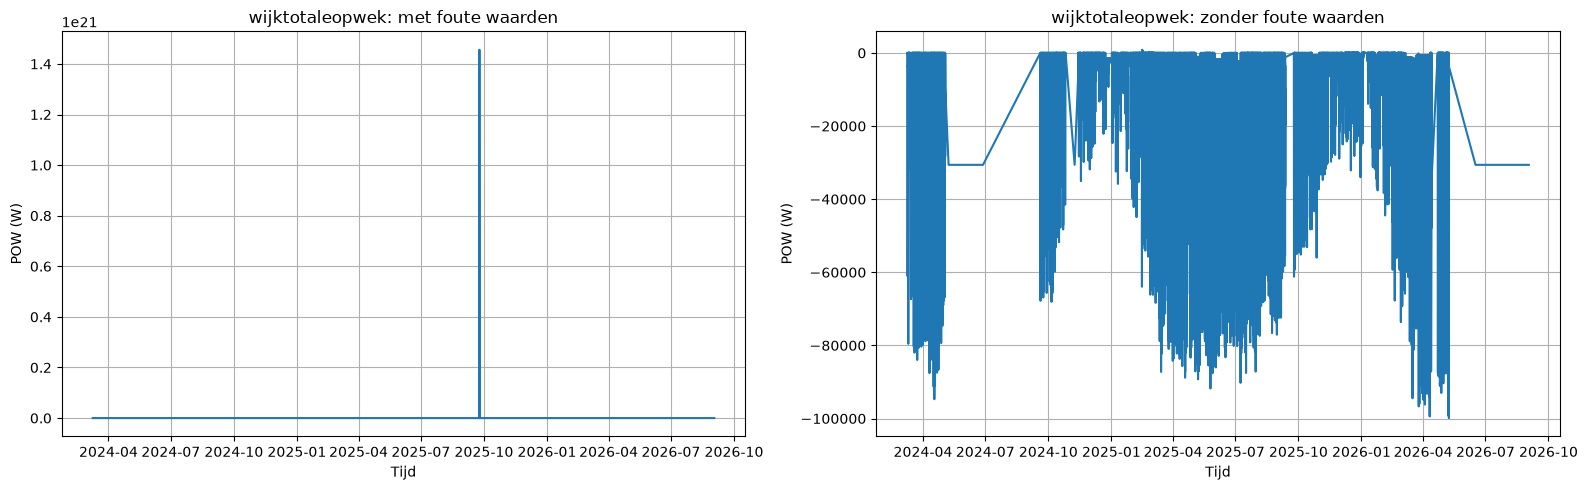

In [237]:
#Het apparaat met de meeste onmogelijke waarden
slechtste = onmogelijk_per_apparaat.index[0]
df_slechtste = df_carport[(df_carport["apparaat_kort"] == slechtste) & df_carport["POW"].notna()].sort_values("timestamp")
goed = df_slechtste["POW"].abs() <= MAX_VERMOGEN

fig, (ax_voor, ax_na) = plt.subplots(1, 2, figsize=(16, 5))

ax_voor.plot(df_slechtste["timestamp"], df_slechtste["POW"])
ax_voor.set_title(f"{slechtste}: met foute waarden")
ax_voor.set_xlabel("Tijd")
ax_voor.set_ylabel("POW (W)")
ax_voor.grid()

ax_na.plot(df_slechtste.loc[goed, "timestamp"], df_slechtste.loc[goed, "POW"])
ax_na.set_title(f"{slechtste}: zonder foute waarden")
ax_na.set_xlabel("Tijd")
ax_na.set_ylabel("POW (W)")
ax_na.grid()

plt.tight_layout()
plt.show()

6. De wijk-meters verwijderen

> Alle waarden boven de grens komen van de drie wijk meters: wijktotaalverbruik, wijktotaleopwek en wijkvirtuelehoofdmeter
>
> Deze meters tellen het verbruik en de opwek van alle huizen in de wijk bij elkaar op. Daardoor liggen hun waarden hoger dan bij de carport
>
> Op 24-09-2025 om 09:50 staat bij twee wijk meters tegelijk een waarde van 1,4·10²¹ W. Dat is wel echt een fout in de data
>
> We gebruiken de wijk meters niet. In dit project bestaat "de wijk" uit de drie locaties waarvan we data hebben (huis, middenhuis en carport). Het verbruik en de opwek daarvan kunnen we zelf berekenen door deze drie op te tellen
>
> Let op: de wijk meters meten de hele wijk, dus onze optelling van drie locaties is kleiner dan wat de wijk meters lieten zien
>
> Daarom worden de wijk meters hier in zijn geheel verwijderd

In [ ]:
WIJK_METERS = ["wijktotaalverbruik-e4393cd3dfdb", "wijktotaleopwek-e4393cd3dfdb", "wijkvirtuelehoofdmeter-e4393cd3dfdb"]

df_carport = df_carport[~df_carport["ENAME"].isin(WIJK_METERS)]

#Controle: zijn er nog waarden boven de grens?
print("Waarden boven de grens over:", (df_carport["POW"].abs() > MAX_VERMOGEN).sum())

#Overgebleven apparaten met hun laagste en hoogste POW
df_carport.groupby("apparaat_kort")["POW"].agg(["min", "max"])

7. Conclusie

> Na het verwijderen van de wijk-meters zitten er geen onmogelijke POW waarden meer in de data
>
> Alle overgebleven apparaten blijven binnen de 100 kW die de aansluiting van de carport kan leveren